## Transformer

W ostatnim notebooku poznaliśmy mechanizm Attention, który pozwala transformerom skupić się na zależnościach słów. Dzisiaj poznamy całą architekturę i przebieg danych w transformerze.

## Przypomnienie: Co już wiemy
- Attention pozwala każdemu tokenowi „spojrzeć” na inne tokeny w sekwencji
- Multi-Head Attention umożliwia jednoczesne skupienie się na różnych aspektach relacji między tokenami

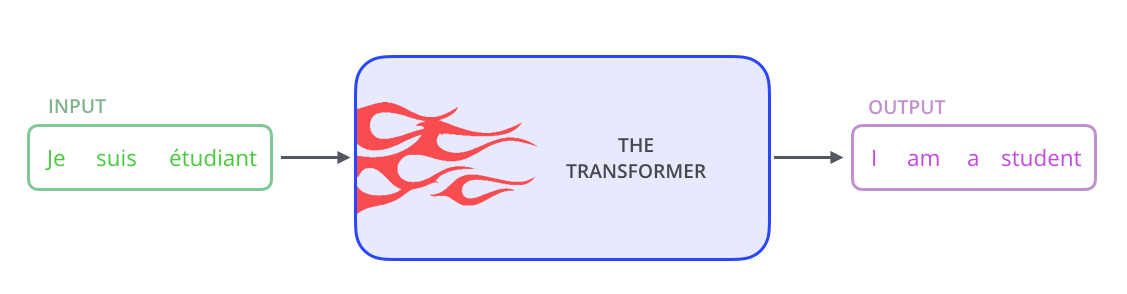

## Architektura Transformera

Pełny model składa się z dwóch części:
1. **Encoder** – przetwarza wejściową sekwencję (np. zdanie źródłowe).
2. **Decoder** – generuje wyjściową sekwencję (np. tłumaczenie).

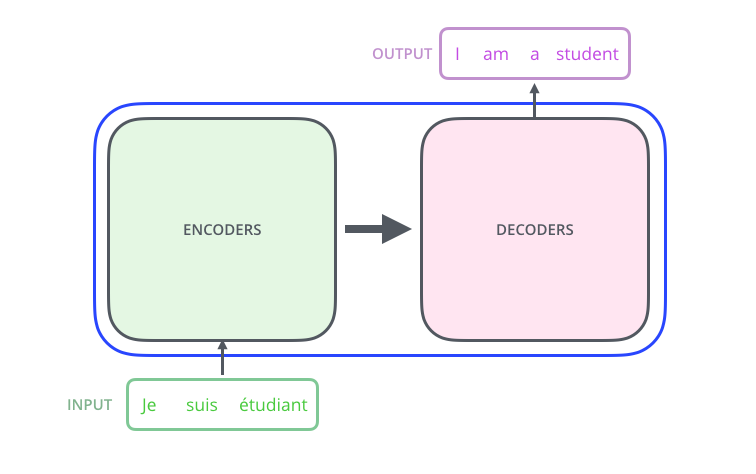


Enkoderów może być dowolna ilość. Po drugiej stronie mamy dekodery - tyle samo co enkoderów.

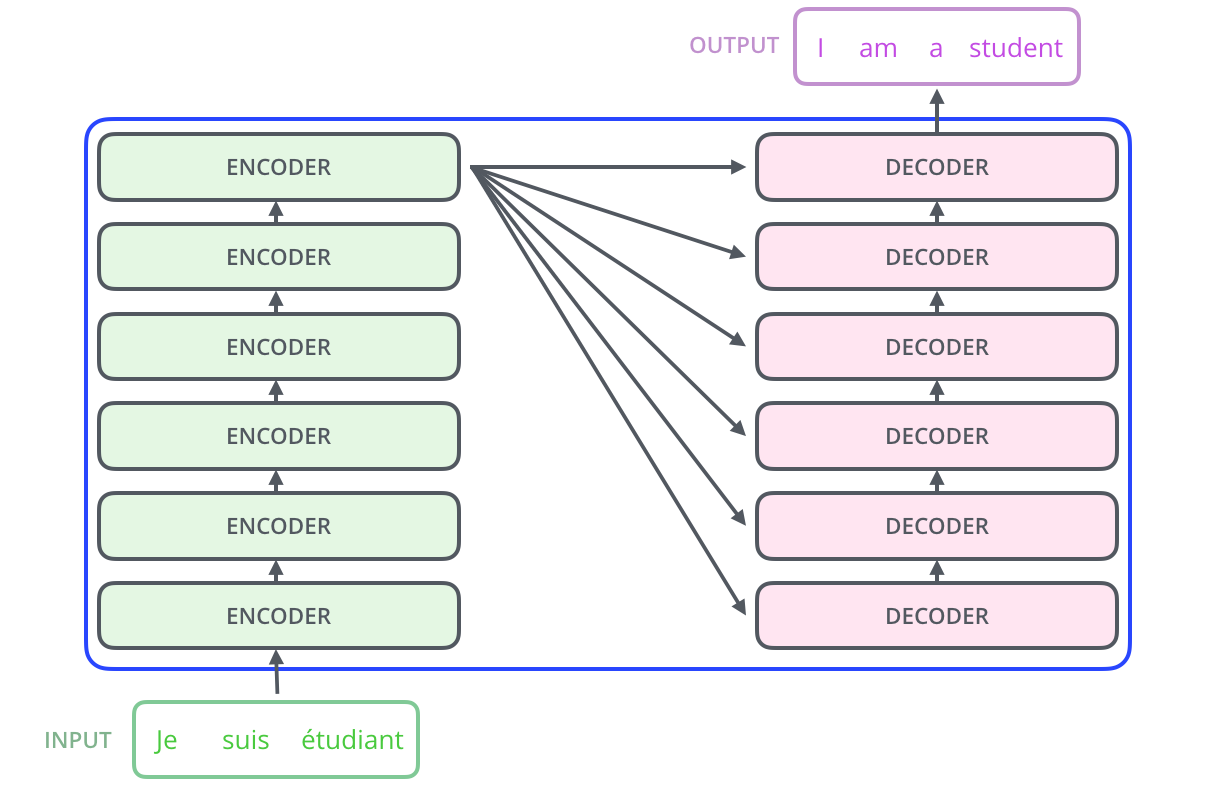

Każdy z nich zawiera powtarzające się bloki (warstwy):
- Encoder Layer = Multi-Head Attention + Feed Forward
- Decoder Layer = Masked Multi-Head Attention + Encoder-Decoder Attention + Feed Forward

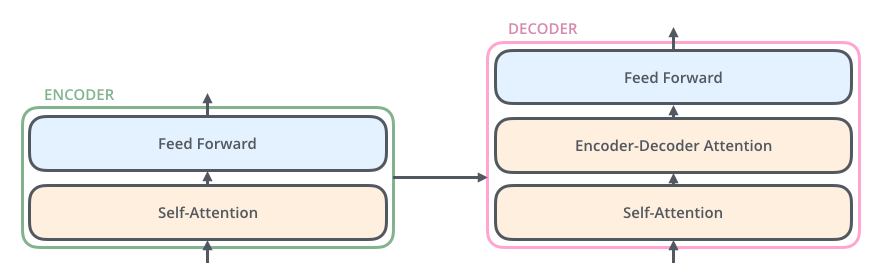

Zanim jednak wejdziemy do pierwszego encodera musimy zembedingować nasz input - i co ważne pamiętać o kolejności

## Flow Transformera

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import math

### 1 Positional Encoding

Transformery, w przeciwieństwie do modeli sekwencyjnych (RNN, LSTM), **nie przetwarzają tokenów w kolejności** — widzą całą sekwencję naraz.  
Dlatego same z siebie **nie wiedzą**, które słowo było pierwsze, a które drugie.

Aby temu zaradzić, do każdego wektora wejściowego (embeddingu słowa) dodajemy **wektor pozycyjny** (*positional encoding*), który zawiera informację o miejscu tokena w zdaniu.

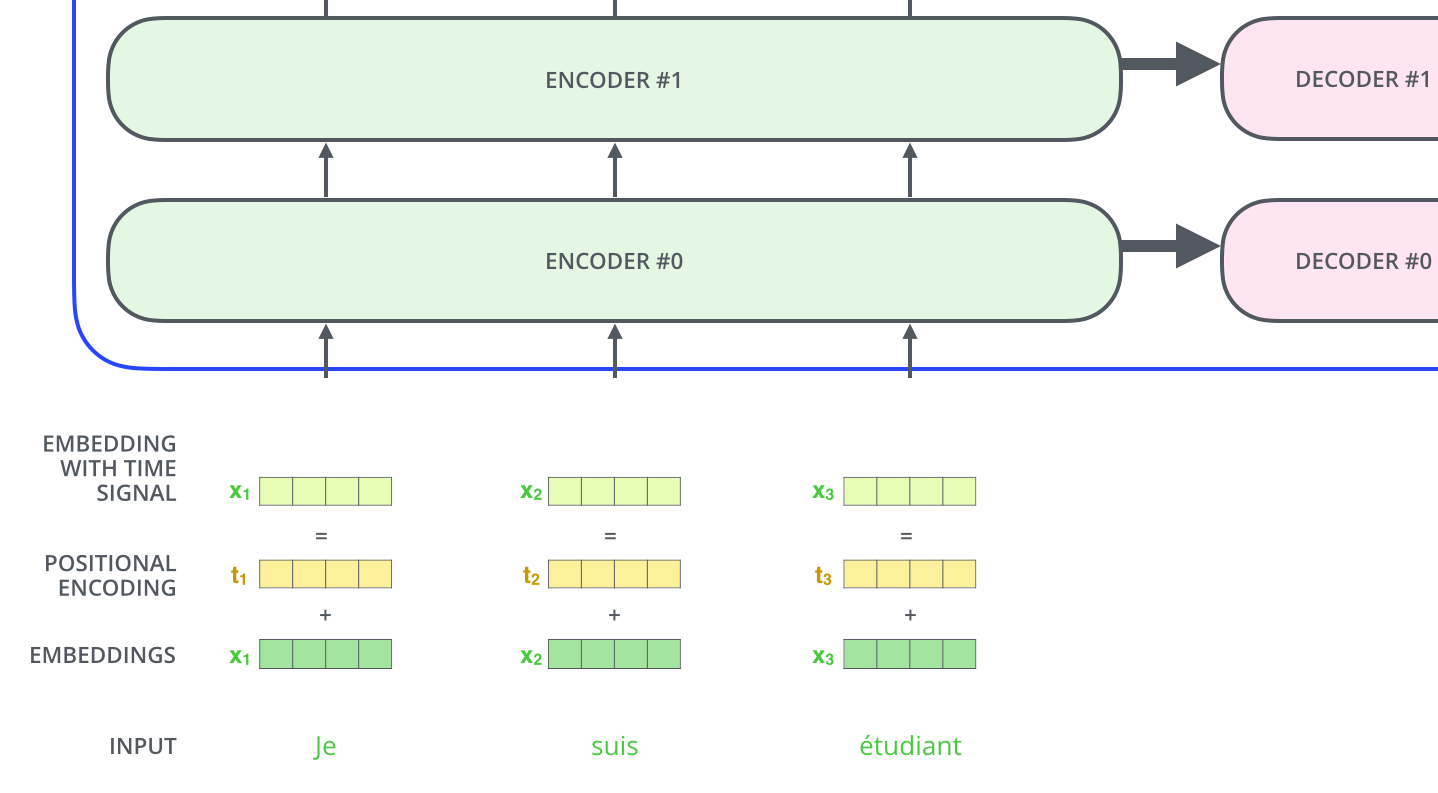

Model dodaje do wektora embeddingu słowa `E_i` wektor pozycyjny `P_i`:

X_i = E_i + P_i


Każdy `P_i` jest deterministycznie obliczany (nie uczymy modelu tego)

Jak to działa?
1. Każda pozycja w zdaniu (np. 0, 1, 2, 3, …) ma swój unikalny wzorzec liczb, który tworzymy za pomocą fal sinus i cosinus o różnych częstotliwościach.
2. Bierzemy numer pozycji tokena w zdaniu (np position = 0)
3. Dla każdego wymiaru embeddingu (np. 64) liczymy dwie wartości: sin i cos.
czyli:
- pos – numer tokena w sekwencji,
- i – numer wymiaru w wektorze (np. 0…63),
- d_model – całkowity rozmiar wektora (np. 64)

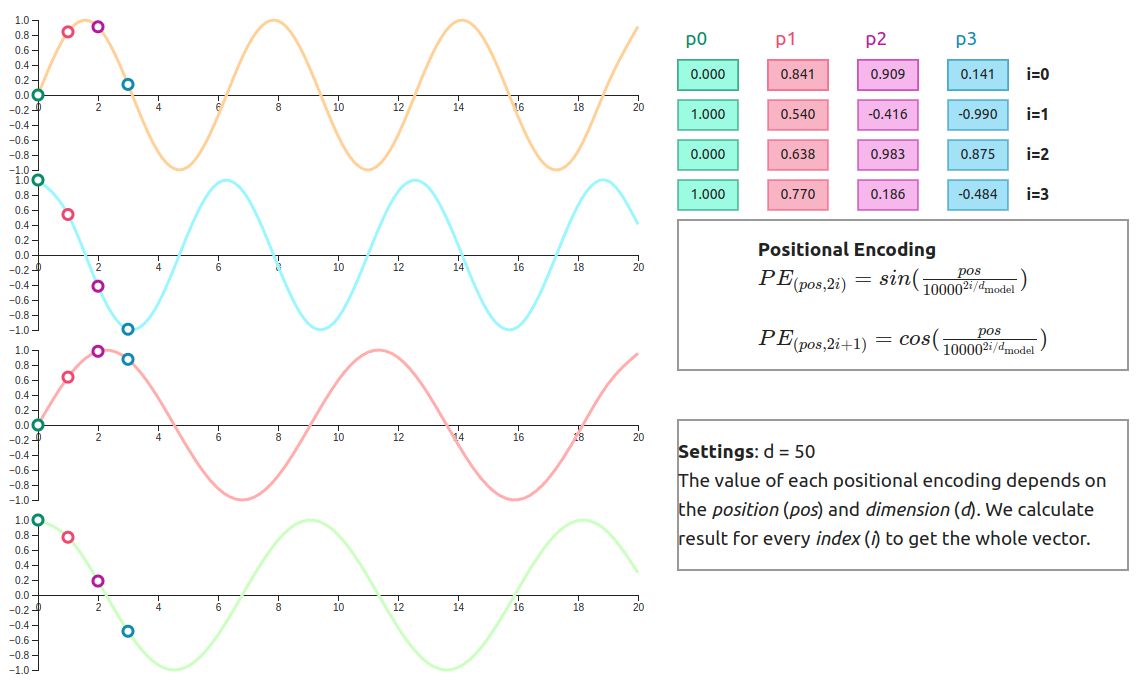

Dodatkowe źródło do nauki: https://erdem.pl/2021/05/understanding-positional-encoding-in-transformers

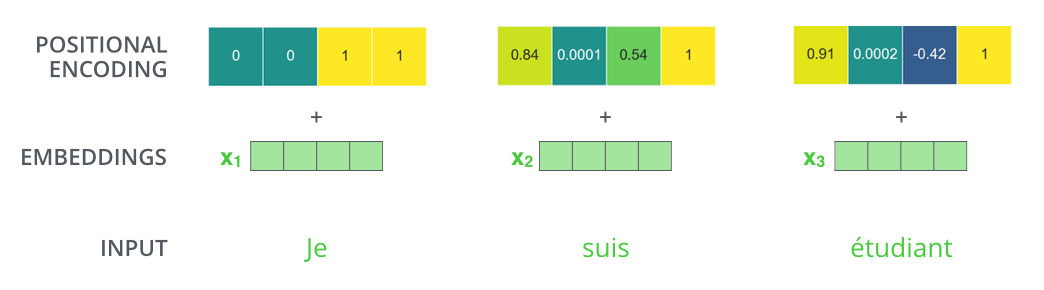

### 2 Encoder:

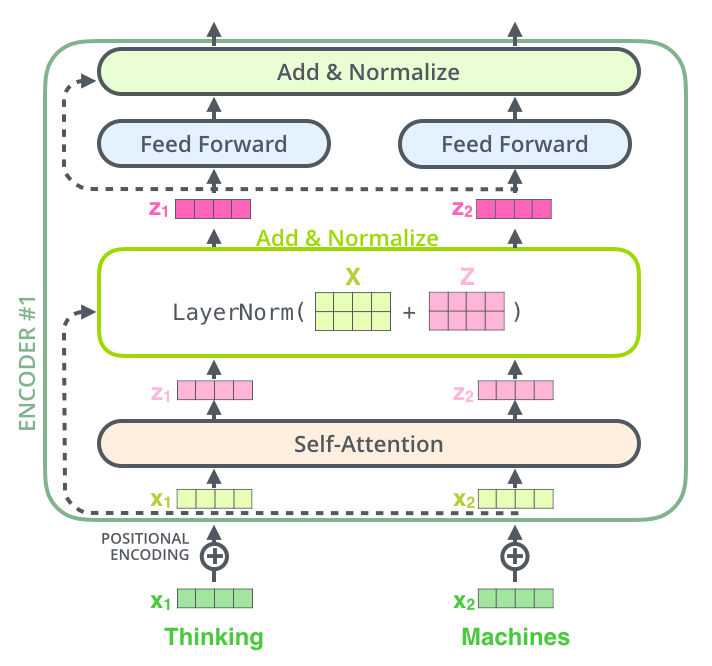


Składa się z:
- **Multi-Head Self-Attention**
- **Add & Norm**
- **Feed Forward Network**
- **Add & Norm**


In [2]:
class TransformerEncoderLayer(nn.Module):
    def __init__(self, d_model, n_heads, dim_feedforward, dropout=0.1):
        super().__init__()
        self.self_attn = nn.MultiheadAttention(d_model, n_heads, dropout=dropout)
        self.linear1 = nn.Linear(d_model, dim_feedforward)
        self.dropout = nn.Dropout(dropout)
        self.linear2 = nn.Linear(dim_feedforward, d_model)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.dropout1 = nn.Dropout(dropout)
        self.dropout2 = nn.Dropout(dropout)

    def forward(self, src):
        attn_output, _ = self.self_attn(src, src, src)
        src = self.norm1(src + self.dropout1(attn_output))
        ff_output = self.linear2(self.dropout(F.relu(self.linear1(src))))
        src = self.norm2(src + self.dropout2(ff_output))
        return src


Przykład przepływy danych:

In [3]:
d_model = 64
n_heads = 8
dim_feedforward = 256
seq_len = 10
batch_size = 2

encoder_layer = TransformerEncoderLayer(d_model, n_heads, dim_feedforward)
x = torch.rand(seq_len, batch_size, d_model)
out = encoder_layer(x)
print("Wejście:", x.shape)
print("Wyjście:", out.shape)


Wejście: torch.Size([10, 2, 64])
Wyjście: torch.Size([10, 2, 64])


### 3 - Decoder

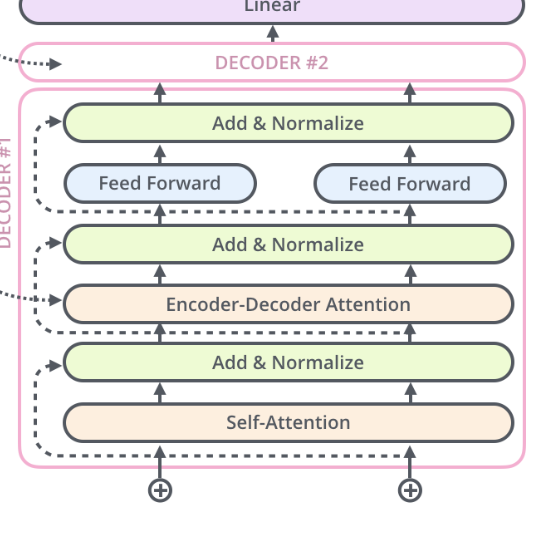

Decoder posiada dwa mechanizmy attention:
- **Masked Self-Attention** (żeby nie podglądać przyszłych tokenów),
- **Encoder-Decoder Attention** – „spojrzenie” na kontekst z encodera.


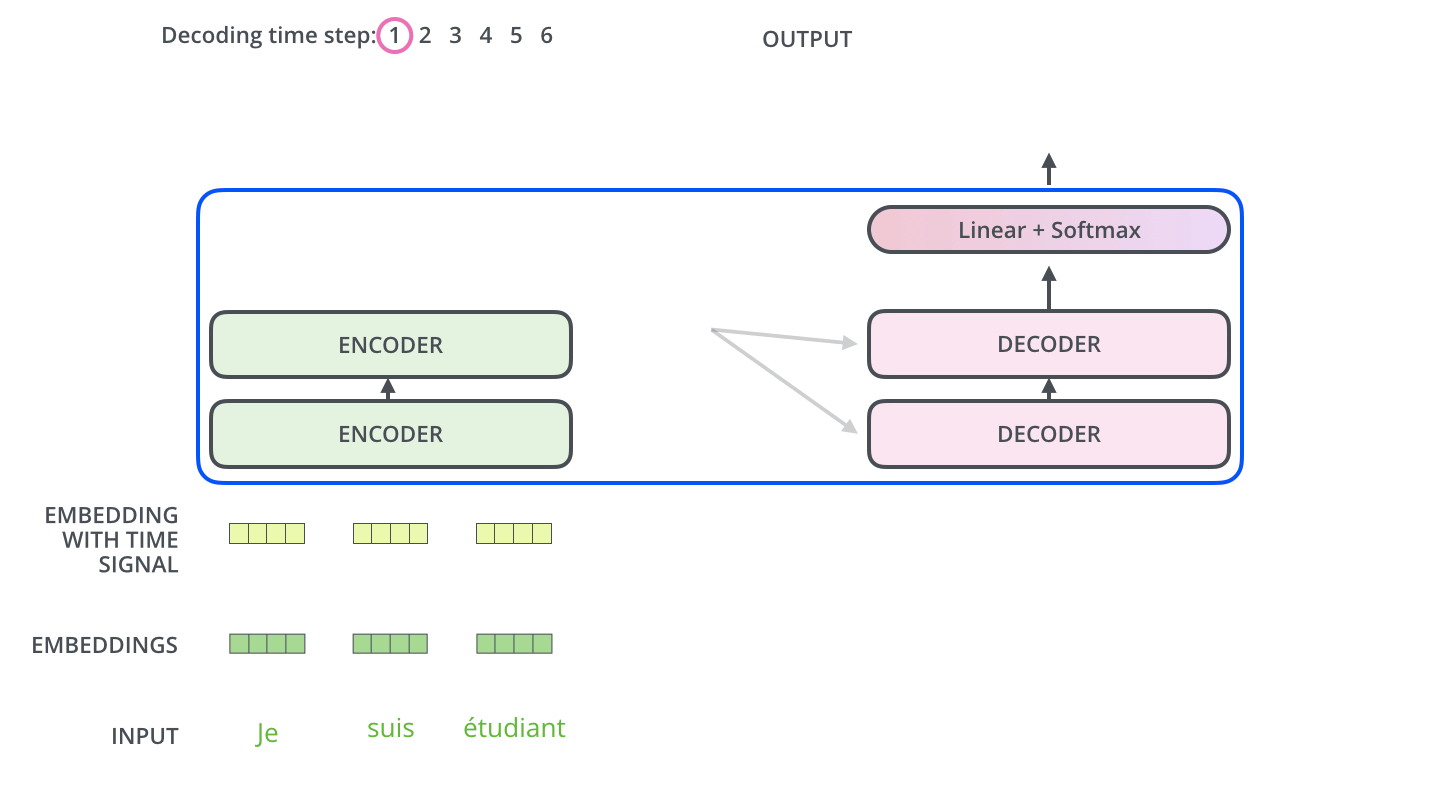

Przypomnienie:

Encoder przetwarza całe wejście (np. zdanie w języku źródłowym) i tworzy zestaw reprezentacji — w postaci par (K,V).

Decoder generuje wyjście (np. tłumaczenie), token po tokenie, i korzysta z tych reprezentacji, żeby „patrzeć” na wejście.

Teraz w decoderze będziemy tworzyć nasze Q (query!)

Animacja:

https://jalammar.github.io/images/t/transformer_decoding_1.gif

https://jalammar.github.io/images/t/transformer_decoding_2.gif

**Masked Self-Attention**:

- Pozwala każdemu tokenowi w sekwencji wyjściowej „zajrzeć” na poprzednie tokeny, ale nie na przyszłe.
- Dzięki temu model może generować tekst autoregsywnie — token po tokenie.

Tak jak w zwykłej rozmowie - wiemy co zostało powiedziane, ale nie wiemy co będzie (możemy tylko zgadywać)

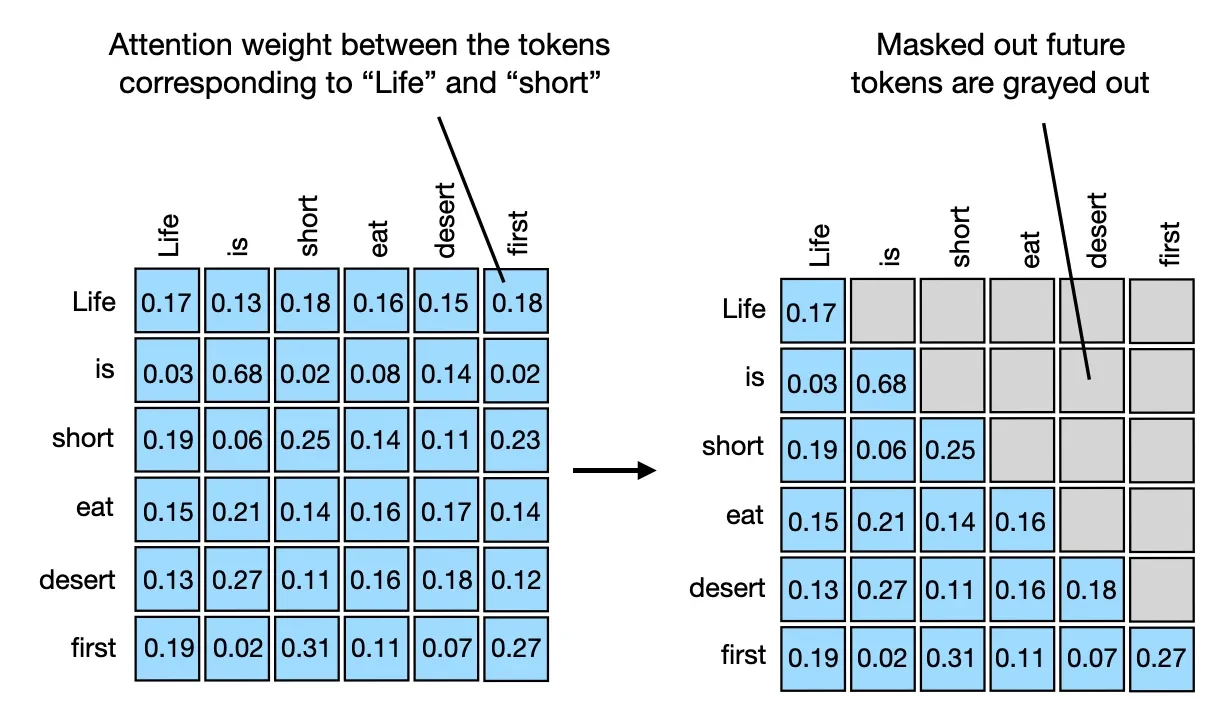

**Encoder–Decoder Attention (Cross-Attention)**

- Pozwala dekoderowi „patrzeć” na wejście przetworzone przez enkoder.
- W tym miejscu łączy się informacja o tym, co już wygenerowano (z dekodera) i co było w wejściu (z enkodera).

W ten sposób dekoder może „zapytać” wejście o to, które słowa są istotne dla bieżącego etapu generacji.

Robimy attention: K i V z encodera a Q z poprzedniego decodera

In [4]:
class TransformerDecoderLayer(nn.Module):
    def __init__(self, d_model, n_heads, dim_feedforward, dropout=0.1):
        super().__init__()
        self.self_attn = nn.MultiheadAttention(d_model, n_heads, dropout=dropout)
        self.cross_attn = nn.MultiheadAttention(d_model, n_heads, dropout=dropout)
        self.linear1 = nn.Linear(d_model, dim_feedforward)
        self.dropout = nn.Dropout(dropout)
        self.linear2 = nn.Linear(dim_feedforward, d_model)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.norm3 = nn.LayerNorm(d_model)
        self.dropout1 = nn.Dropout(dropout)
        self.dropout2 = nn.Dropout(dropout)
        self.dropout3 = nn.Dropout(dropout)

    def forward(self, tgt, memory):
        # Masked self-attention
        tgt2, _ = self.self_attn(tgt, tgt, tgt)
        tgt = self.norm1(tgt + self.dropout1(tgt2))

        # Encoder-Decoder attention
        tgt2, _ = self.cross_attn(tgt, memory, memory)
        tgt = self.norm2(tgt + self.dropout2(tgt2))

        # Feed Forward
        tgt2 = self.linear2(self.dropout(F.relu(self.linear1(tgt))))
        tgt = self.norm3(tgt + self.dropout3(tgt2))
        return tgt

### 4 - Linear i Softmax - wyjście

Na koniec (po wszystkich encoderach i decoderach) jako ostatnie wyjście z osttaniego decodera mamy jakiś wektor liczb

Model następnie przekształca to na przestrzeń słów słownika - surowe logitsy.

Logity to mogą być losowe liczby - należy więc je przekształcić w prawdopodobieństwa - Softmax

Wybieramy, które słowo jest najbardziej prawdopodobne

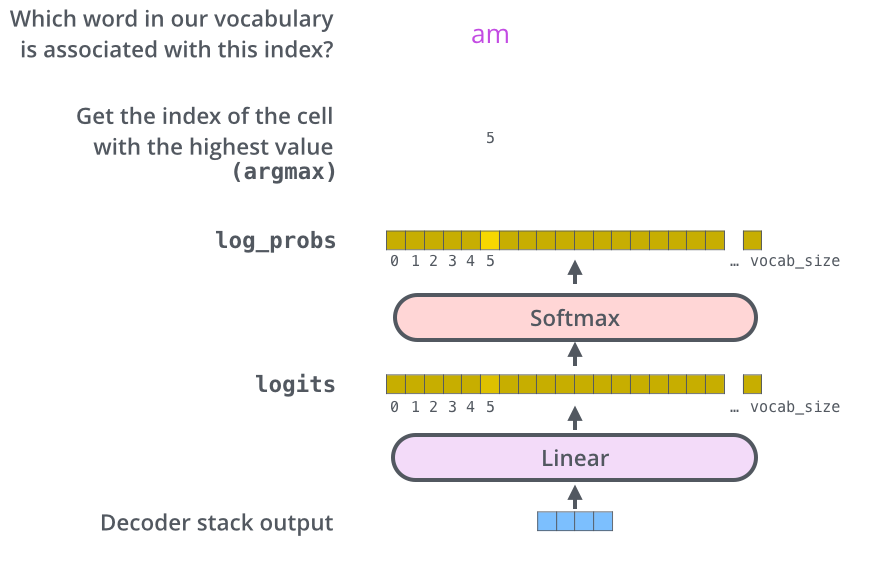

I oto cała tajemnica transformerów :)


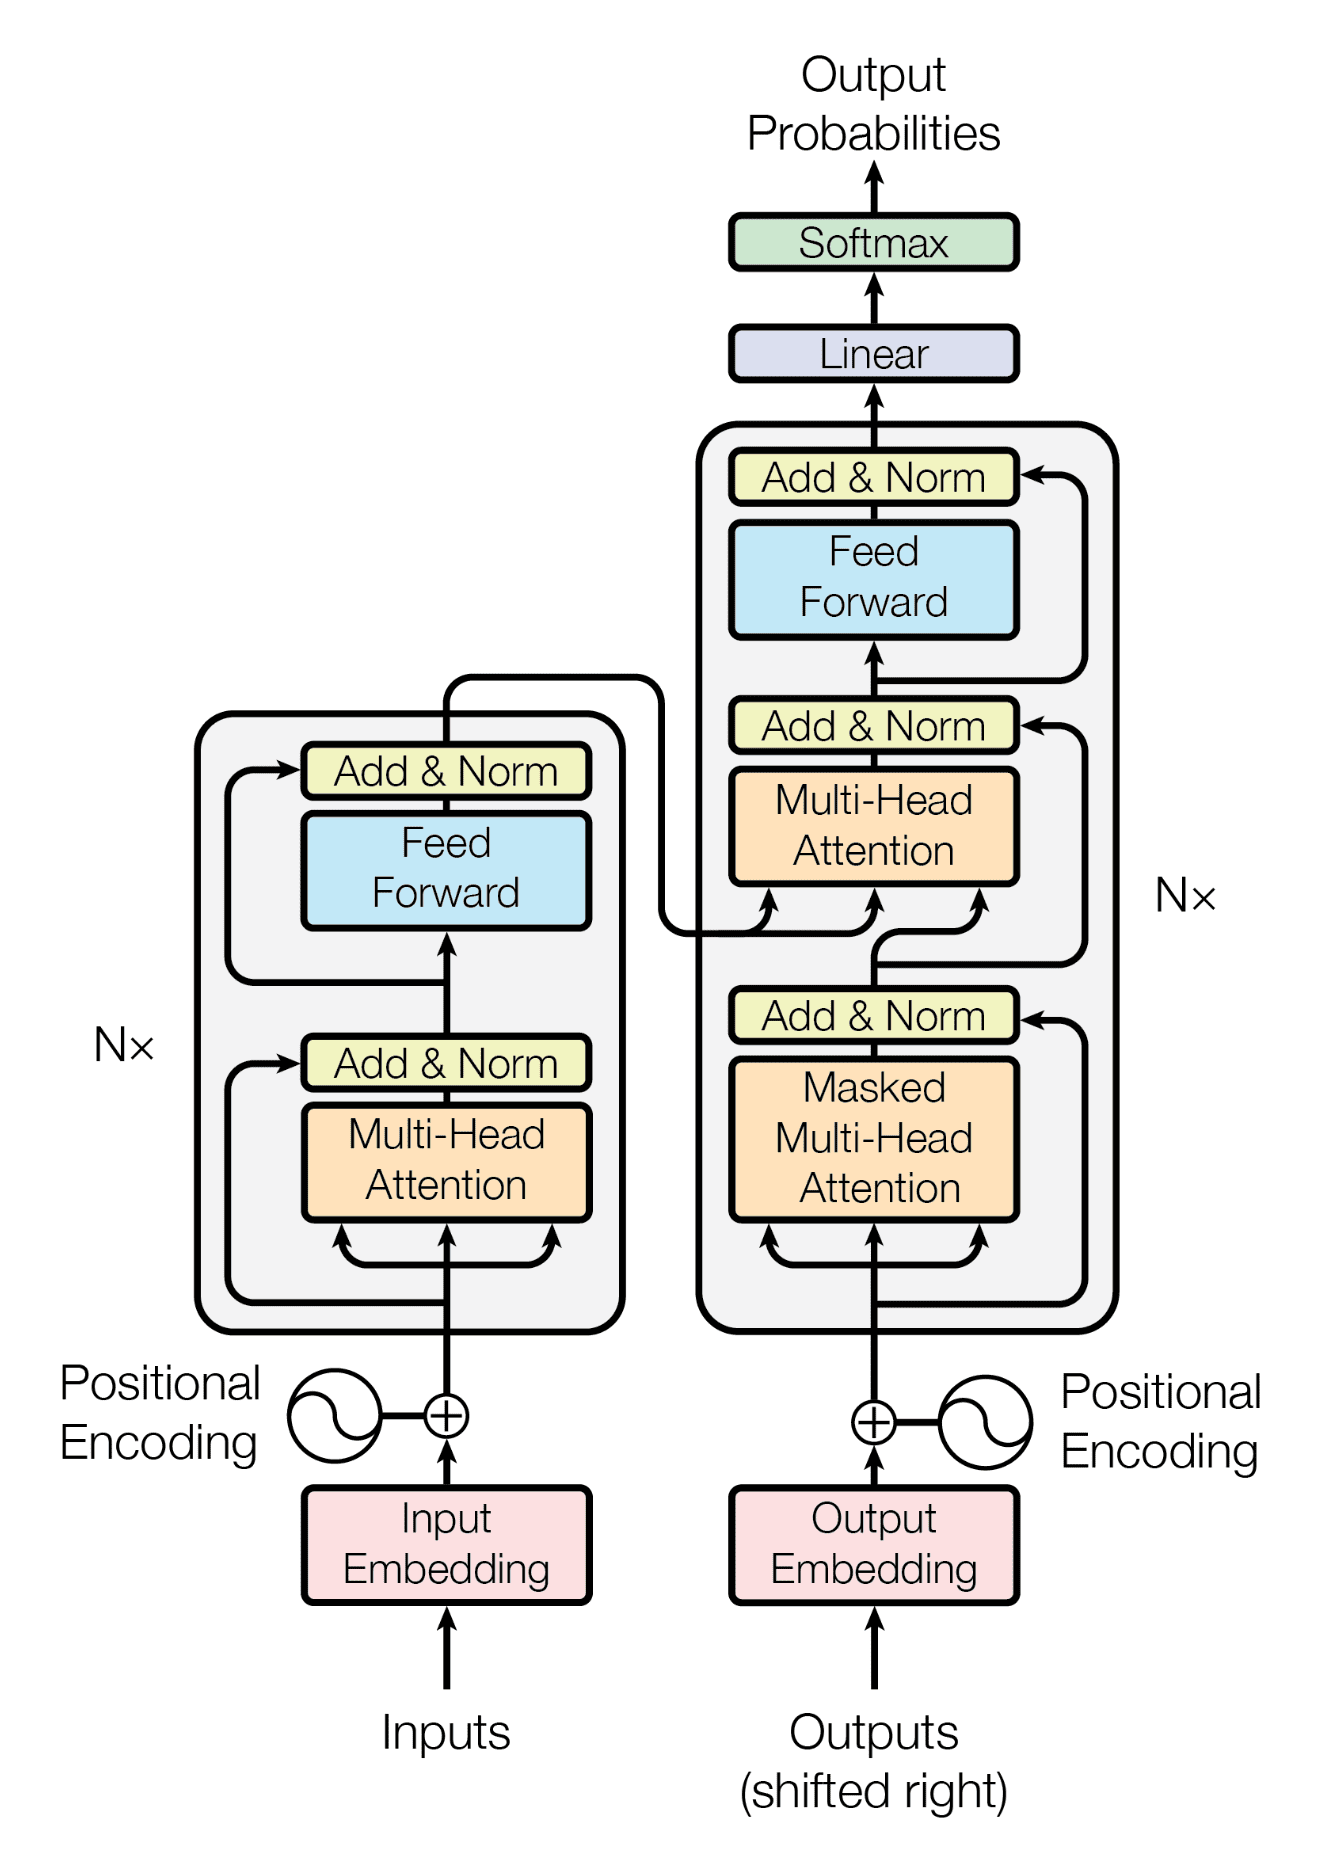

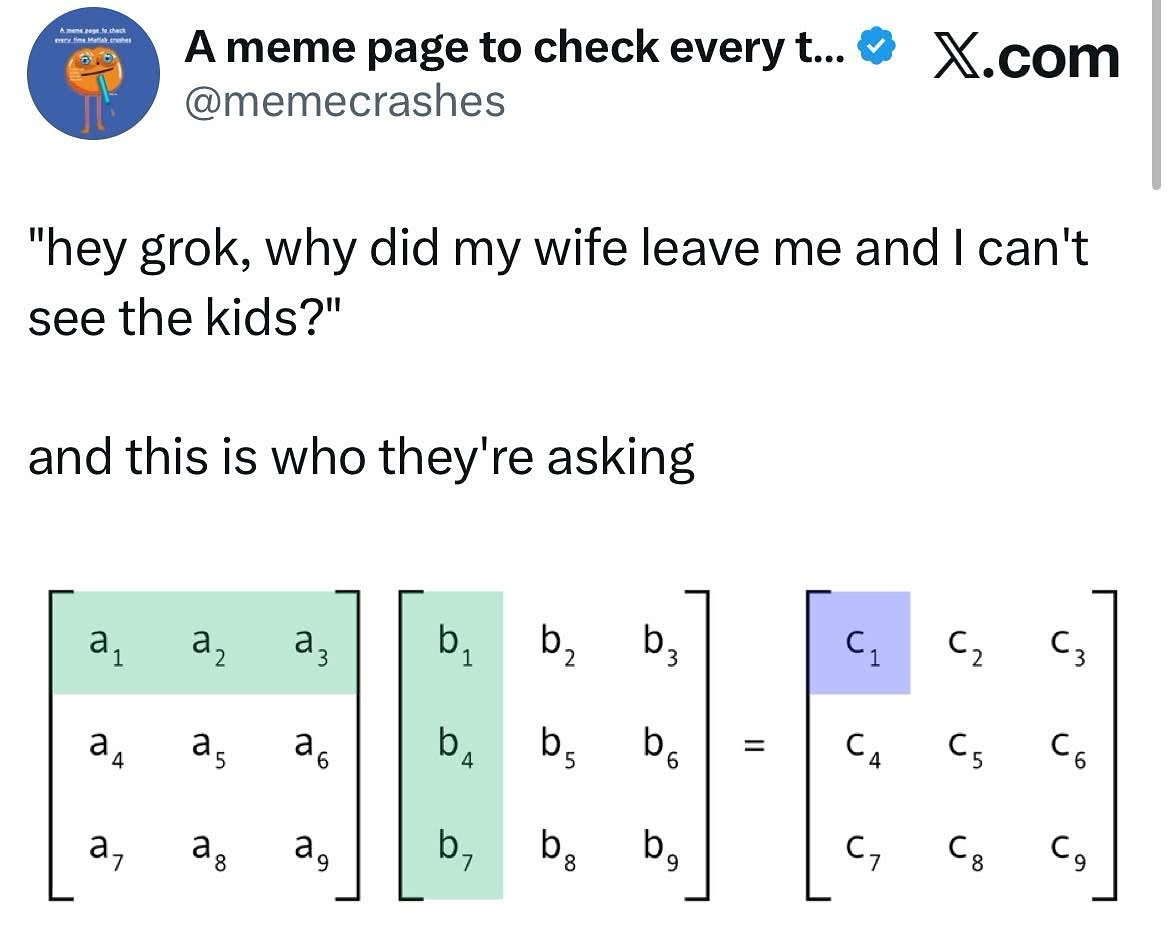

# Zadania

## Zadanie 1

Dodaj Masking do Self-Attention (dla dekodera)

- Napisz funkcję generate_subsequent_mask(size) — tworzącą trójkątną maskę (1 tam, gdzie można patrzeć, 0 gdzie nie).
- Dodaj tę maskę do obliczeń QK^T przed softmaxem (ustawiając zabronione pozycje na -inf).

In [5]:
import torch
import torch.nn.functional as F

def generate_subsequent_mask(size):
    """
    Tworzy trójkątną maskę dla self-attention w dekoderze.
    1 = można patrzeć (bieżące i wcześniejsze pozycje)
    0 = zabronione (przyszłe pozycje)
    """
    mask = torch.tril(torch.ones(size, size))
    return mask

def masked_attention(Q, K, V, mask):
    d_k = Q.shape[-1]
    scores = torch.matmul(Q, K.transpose(1, 2)) / torch.sqrt(torch.tensor(d_k, dtype=torch.float32))
    scores = scores.masked_fill(mask == 0, float('-inf'))
    attn = F.softmax(scores, dim=-1)
    output = torch.matmul(attn, V)
    return output, attn

# 🔹 Test działania
Q = torch.rand(1, 4, 8)  # (batch, seq_len, d_model)
K = torch.rand(1, 4, 8)
V = torch.rand(1, 4, 8)

mask = generate_subsequent_mask(4)
print("Mask:\n", mask)

output, attn = masked_attention(Q, K, V, mask)

print("\nAttention weights (softmaxed):\n", attn)
print("\nOutput shape:", output.shape)


Mask:
 tensor([[1., 0., 0., 0.],
        [1., 1., 0., 0.],
        [1., 1., 1., 0.],
        [1., 1., 1., 1.]])

Attention weights (softmaxed):
 tensor([[[1.0000, 0.0000, 0.0000, 0.0000],
         [0.4858, 0.5142, 0.0000, 0.0000],
         [0.3611, 0.3479, 0.2910, 0.0000],
         [0.2463, 0.2404, 0.2263, 0.2870]]])

Output shape: torch.Size([1, 4, 8])


## Zadanie 2

Zbuduj i przetrenuj własnego mini-Transformera w PyTorchu

Parametry modelu:

In [6]:
import torch
from torch import nn
import torch.optim as optim
import torch.nn.functional as F

d_model = 64
num_heads = 4
num_layers = 2
vocab_size = 20
max_len = 10
device = "cuda" if torch.cuda.is_available() else "cpu"

Sztuczne dane:

In [7]:
def generate_data(batch_size=32, seq_len=6):
    src = torch.randint(1, vocab_size, (batch_size, seq_len))
    tgt = src.clone()
    return src, tgt

src, tgt = generate_data()
print(src[0])

tensor([ 9,  5, 12,  5,  1,  6])


In [8]:
def positional_encoding(max_len, d_model):
    pe = torch.zeros(max_len, d_model)
    for pos in range(max_len):
        for i in range(0, d_model, 2):
            angle = pos / (10000 ** (i / d_model))
            pe[pos, i] = math.sin(angle)
            pe[pos, i + 1] = math.cos(angle)
    return pe

class MiniTransformer(nn.Module):
    def __init__(self, vocab_size, d_model, num_heads, num_layers, max_len, dim_feedforward):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, d_model)

        # 1 - Positional Encoding
        self.pe = positional_encoding(max_len, d_model).to(device)

        # 2 - Encoder
        self.encoder_layers = nn.ModuleList([TransformerEncoderLayer(d_model, num_heads, dim_feedforward) for _ in range(num_layers)])

        # 3 - Decoder
        self.decoder_layers = nn.ModuleList([TransformerDecoderLayer(d_model, num_heads, dim_feedforward) for _ in range(num_layers)])

        # 4 - Linear
        self.fc = nn.Linear(d_model, vocab_size)

    def forward(self, src, tgt):
        # X_i = E_i + P_i
        src = self.embedding(src) + self.pe[:src.shape[1]]
        tgt = self.embedding(tgt) + self.pe[:tgt.shape[1]]

        # (batch, seq, d_model) -> (seq, batch, d_model)
        src = src.transpose(0, 1)
        tgt = tgt.transpose(0, 1)

        for layer in self.encoder_layers:
            src = layer(src)

        for layer in self.decoder_layers:
            tgt = layer(tgt, src)

        return self.fc(tgt.transpose(0, 1))

In [9]:
dim_feedforward = 256
model = MiniTransformer(vocab_size, d_model, num_heads, num_layers, max_len, dim_feedforward).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

EPOCHS = 500
for epoch in range(EPOCHS):
    src, tgt = generate_data()
    src, tgt = src.to(device), tgt.to(device)

    tgt_input = tgt.clone()
    tgt_input[:, 1:] = tgt[:, :-1]
    tgt_input[:, 0] = 0

    optimizer.zero_grad()
    output = model(src, tgt_input)
    loss = criterion(output.view(-1, vocab_size), tgt.view(-1))
    loss.backward()
    optimizer.step()
    if (epoch + 1) % 100 == 0:
        print(f"Epoch {epoch+1}/{EPOCHS}, Loss: {loss.item():.4f}")

Epoch 100/500, Loss: 0.6943
Epoch 200/500, Loss: 0.0462
Epoch 300/500, Loss: 0.0224
Epoch 400/500, Loss: 0.0145
Epoch 500/500, Loss: 0.0098
